# Energy Intelligence AI · MVP e Forecast V2

Este notebook complementa `01_exploratory_analysis.ipynb`, preservado com suas
análises e resultados. A lógica de produção está em `src/`; API e dashboard
reutilizam os mesmos modelos persistidos. Execute `python -m src.train` na raiz
antes desta análise. Não há treino automático na inferência.

**Protocolo:** treino nos primeiros 80% da série; seleção do candidato por três
janelas de `TimeSeriesSplit` dentro do treino; teste nos 20% finais. As previsões
são de um passo (15 minutos), com observações reais anteriores ao instante.


In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/inference.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.utils import DATASET_PATH, MODEL_DIR, OUTPUT_DIR
from src.data_processing import load_data
from src.feature_engineering import build_forecast_features
from src.inference import EnergyPipeline
from src.forecasting import evaluate_forecast
from src.anomaly_detection import evaluate_anomaly_model

raw = load_data(DATASET_PATH, require_electrical=True)
pipeline = EnergyPipeline.load(MODEL_DIR)
metrics = json.loads((MODEL_DIR / "metrics.json").read_text(encoding="utf-8"))
print(f"{len(raw)} registros | {raw.is_anomaly.sum()} eventos reais | 15 minutos")
print("Candidato principal:", metrics["forecast_selection"])


2880 registros | 20 eventos reais | 15 minutos
Candidato principal: baseline_profile


## Features causais

`lag_1`, `lag_4`, `lag_96` e `lag_672` correspondem a 15 minutos, 1 hora, 24 horas
e 7 dias. Médias e desvios móveis usam `shift(1)` antes de `rolling`.
Medianas horárias são ajustadas apenas no treino e congeladas junto aos modelos.
Lacunas permanecem indisponíveis. V2 exige todas as suas features históricas;
o baseline diário exige somente a medição de 24 horas atrás. Esses candidatos
usam fallback V1 quando faltam as features exigidas. V1 e o perfil congelado
do treino não exigem histórico fornecido na inferência.


In [2]:
features = build_forecast_features(raw)
features.iloc[672:677]


,hour,minute,weekday,day,month,lag_1,lag_4,lag_96,lag_672,rolling_mean_4,rolling_std_4,rolling_mean_96,rolling_std_96
672,0,0,3,8,1,3.699,3.394,1.544,1.560,3.57950,0.166206,5.537000,3.057376
673,0,15,3,8,1,1.468,3.739,1.458,1.683,3.09800,1.092326,5.536208,3.058431
674,0,30,3,8,1,1.351,3.486,1.596,1.690,2.50100,1.264254,5.535094,3.059952
675,0,45,3,8,1,1.663,3.699,1.372,1.565,2.04525,1.109986,5.535792,3.059051
676,1,0,3,8,1,1.522,1.468,1.487,1.529,1.50100,0.129453,5.537354,3.056940


In [3]:
# A própria observação prevista e as futuras não alteram suas features.
changed = raw.copy()
changed.loc[1000:, "active_power_kw"] *= 100
pd.testing.assert_frame_equal(features.iloc[:1001], build_forecast_features(changed).iloc[:1001])
print("Verificação causal aprovada.")


Verificação causal aprovada.


## Forecast V1 × V2 × baselines

Comparação no mesmo holdout e com os mesmos timestamps. V1 mantém as 200 árvores
RandomForest e features temporais originais. V2 adiciona histórico com folhas
mínimas de quatro amostras. Baseline diário usa a observação de 24 horas antes;
baseline perfil usa mediana de hora e tipo de dia útil/fim de semana do treino.
O candidato principal é escolhido pelo menor MAE médio da validação, sem olhar
as métricas de holdout. ML só é preferido quando supera a referência simples.


In [4]:
comparison = pd.DataFrame(metrics["forecast_holdout"]).T
comparison.rename(columns={"mae_kw":"MAE (kW)", "rmse_kw":"RMSE (kW)", "r2":"R²"}).round(4)


,MAE (kW),RMSE (kW),R²
forecast_v1,0.5099,1.1495,0.8716
forecast_v2,0.4806,1.0645,0.8899
baseline_daily,0.8707,1.7987,0.6855
baseline_profile,0.4126,0.9879,0.9051


In [5]:
cv = pd.DataFrame({name: {f"{metric}_{stat}": value for metric, stats in scores.items()
    for stat, value in stats.items()} for name, scores in metrics["forecast_cv"].items()}).T
cv.round(4)


,mae_kw_mean,mae_kw_std,rmse_kw_mean,rmse_kw_std,r2_mean,r2_std
forecast_v1,0.4884,0.0476,1.0069,0.1652,0.8884,0.0366
forecast_v2,0.4723,0.0412,0.9221,0.0849,0.9084,0.0204
baseline_daily,0.9153,0.3167,1.5349,0.4474,0.7228,0.1450
baseline_profile,0.3729,0.0090,0.8076,0.1330,0.9279,0.0258


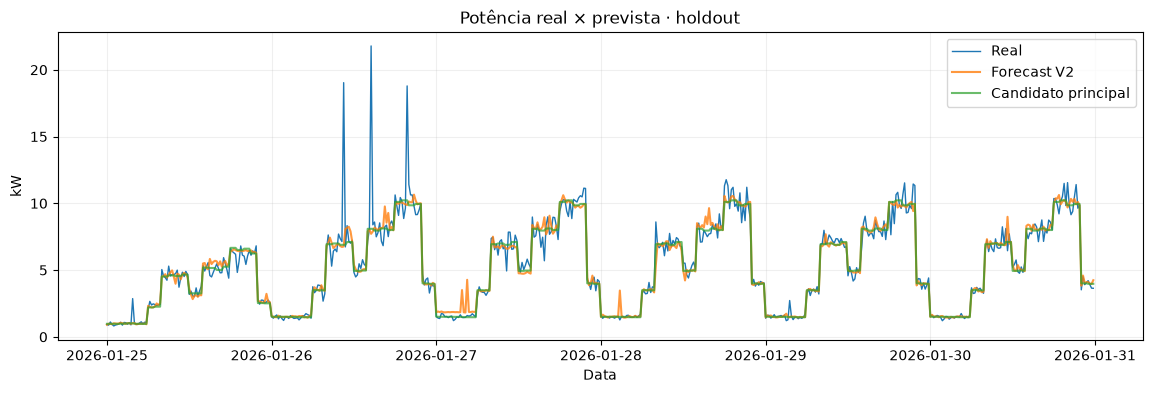

In [6]:
predictions = pd.read_csv(OUTPUT_DIR / "forecast_results.csv", parse_dates=["timestamp"])
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(predictions.timestamp, predictions.active_power_kw, label="Real", linewidth=1)
ax.plot(predictions.timestamp, predictions.forecast_v2, label="Forecast V2", alpha=.8)
ax.plot(predictions.timestamp, predictions.expected_power_kw, label="Candidato principal", alpha=.7)
ax.set(title="Potência real × prevista · holdout", ylabel="kW", xlabel="Data")
ax.legend(); ax.grid(alpha=.2)
plt.show()


## Detecção contextual, score e severidade

O resultado histórico V2 do notebook original (precision/recall/F1 ≈ 80%) foi
obtido ajustando e avaliando no mesmo dataset. Abaixo está uma avaliação distinta,
fora do treino. Existem somente cinco anomalias reais no holdout: métricas ainda
instáveis e sem evidência de generalização para instalações reais.

O score usa `-decision_function`, normalizado pelos mínimos/máximos **do treino**
e limitado a 0–100. Não é probabilidade. Somente detecções recebem Baixo (<40),
Moderado (<60), Alto (<80), Crítico (≥80); demais observações são Normal.
Mensagens descrevem potência, referência histórica e desvio, sem diagnosticar causas.


In [7]:
results = pipeline.analyze(raw)
holdout = results.loc[~results.model_training_overlap]
print(evaluate_anomaly_model(holdout, holdout.is_anomaly_prediction))
holdout.loc[holdout.is_anomaly_prediction.eq(1), ["timestamp", "active_power_kw",
    "potencia_mediana_hora", "anomaly_score", "severity", "event_message"]]


{'evaluated_rows': 576, 'precision': 0.5555555555555556, 'recall': 1.0, 'f1': 0.7142857142857143, 'true_positives': 5, 'false_positives': 4, 'false_negatives': 0, 'true_negatives': 567, 'confusion_matrix': [[567, 4], [0, 5]]}


,timestamp,active_power_kw,potencia_mediana_hora,anomaly_score,severity,event_message
2319,2026-01-25 03:45:00,2.864,1.4445,69.482876,Alto,Comportamento anômalo — severidade Alto. Potên...
2382,2026-01-25 19:30:00,6.807,9.7655,58.093238,Moderado,Comportamento anômalo — severidade Moderado. P...
2442,2026-01-26 10:30:00,19.034,6.5155,93.898100,Crítico,Comportamento anômalo — severidade Crítico. Po...
2458,2026-01-26 14:30:00,21.784,7.7005,100.000000,Crítico,Comportamento anômalo — severidade Crítico. Po...
2479,2026-01-26 19:45:00,18.790,9.7655,85.772678,Crítico,Comportamento anômalo — severidade Crítico. Po...
2480,2026-01-26 20:00:00,11.412,9.5605,61.900312,Alto,Comportamento anômalo — severidade Alto. Potên...
2624,2026-01-28 08:00:00,8.605,6.6510,63.001435,Alto,Comportamento anômalo — severidade Alto. Potên...
2702,2026-01-29 03:30:00,2.719,1.4445,57.621492,Moderado,Comportamento anômalo — severidade Moderado. P...
2869,2026-01-30 21:15:00,11.402,9.6035,60.437891,Alto,Comportamento anômalo — severidade Alto. Potên...


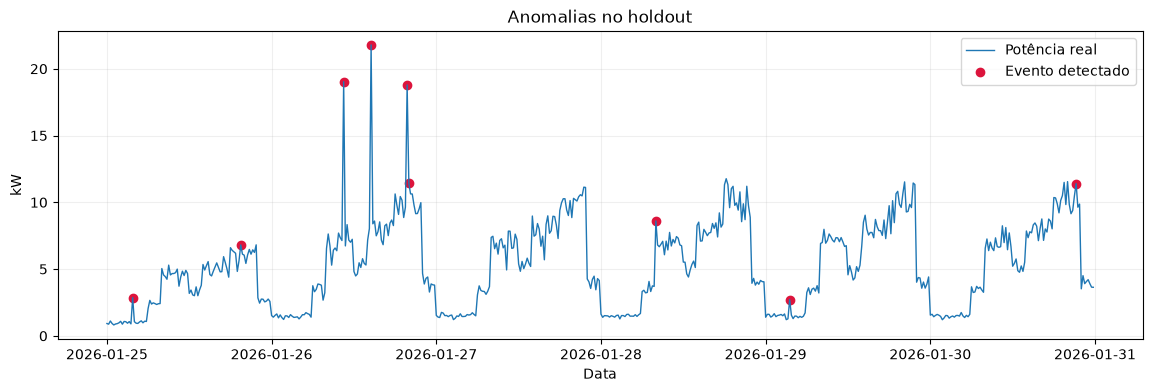

In [8]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(holdout.timestamp, holdout.active_power_kw, label="Potência real", linewidth=1)
events = holdout.loc[holdout.is_anomaly_prediction.eq(1)]
ax.scatter(events.timestamp, events.active_power_kw, color="crimson", label="Evento detectado")
ax.set(title="Anomalias no holdout", ylabel="kW", xlabel="Data")
ax.legend(); ax.grid(alpha=.2)
plt.show()


## Importância de features

Importância interna do RandomForest V2 não demonstra causalidade. O modelo é
comparado com referências simples e pode permanecer como candidato experimental.


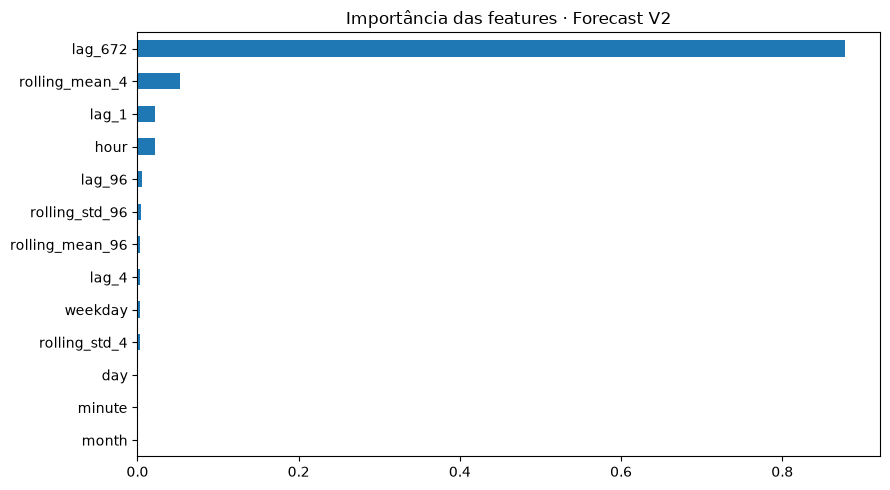

In [9]:
importance = pd.Series(metrics["feature_importance_v2"]).sort_values()
importance.plot.barh(figsize=(9, 5), title="Importância das features · Forecast V2")
plt.tight_layout(); plt.show()


## Inferência reutilizável

`analyze` retorna as medições, previsão, erro, detecção, score, severidade e
mensagem. `forecast_next` prevê o próximo intervalo de 15 minutos a partir do
histórico fornecido. V1 e perfil congelado não exigem histórico adicional;
diário/V2 indicam fallback V1 somente quando faltam as features exigidas.
As linhas sobrepostas ao treino são marcadas por `model_training_overlap`.


In [10]:
pipeline.forecast_next(raw)


{'timestamp': '2026-01-31T00:00:00',
 'predicted_power_kw': 0.9755,
 'forecast_source': 'baseline_profile',
 'model_training_overlap': False}

## Execução do produto

```bash
python -m src.train
python -m uvicorn app.api:app --reload
python -m streamlit run app/dashboard.py
python -m pytest -q
```

A API inclui `/health`, `/predict/anomaly`, `/predict/forecast`, `/analyze` e
`/docs`. O dashboard carrega o demo automaticamente e permite upload de CSV,
filtros, gráficos interativos e exportação da análise/eventos.
